In [1]:
import pathlib
import sys

from matplotlib import pyplot as plt

# the analysis code lives in r60d05_el_hckcr1_analysis.py next to this notebook
# (run it as a script to regenerate everything: python r60d05_el_hckcr1_analysis.py)
sys.path.insert(0, str(pathlib.Path.cwd()))
import r60d05_el_hckcr1_analysis as ana

plt.rcParams['pdf.fonttype'] = 42

%load_ext autoreload
%autoreload 2
%matplotlib inline

In [2]:
sess_manager = ana.load_session_manager()     # folders: see ana.BASEDIR, ana.DEFAULT_FIGDIR
sess_manager.sess_df.head()

,date,fly,sess,condition,scan_type,usable,notes,session,fly_id
0,19_11_2024,fly1,baseline-000,hckcr1,baseline,1,NaN,baseline-000,19_11_2024_fly1_condition_hckcr1
1,19_11_2024,fly1,remap_0deg-001,hckcr1,remap_0deg,1,NaN,remap_0deg-001,19_11_2024_fly1_condition_hckcr1
2,19_11_2024,fly1,post_0deg-002,hckcr1,post_0deg,1,NaN,post_0deg-002,19_11_2024_fly1_condition_hckcr1
3,19_11_2024,fly1,remap_180deg-003,hckcr1,remap_180deg,1,NaN,remap_180deg-003,19_11_2024_fly1_condition_hckcr1
4,19_11_2024,fly1,post_180deg-004,hckcr1,post_180deg,1,NaN,post_180deg-004,19_11_2024_fly1_condition_hckcr1


## Optogenetic responses

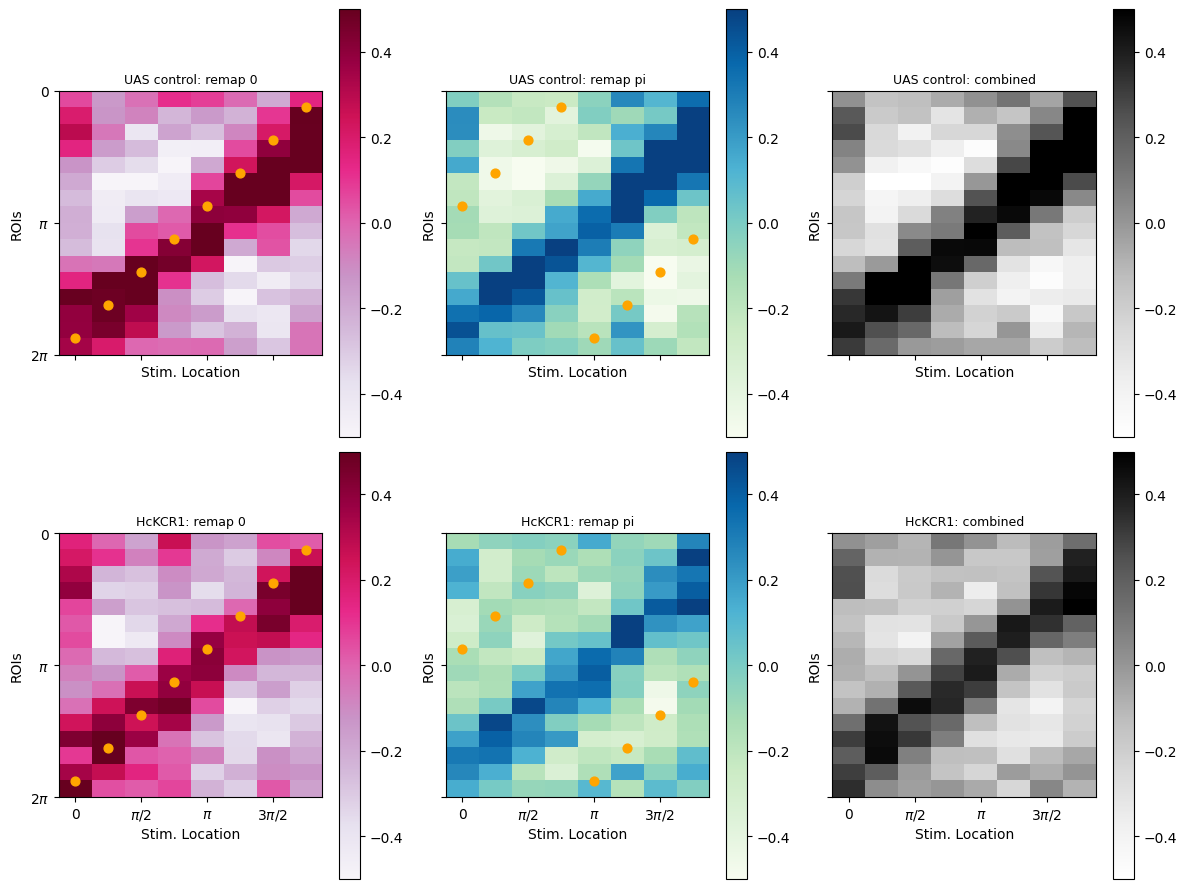

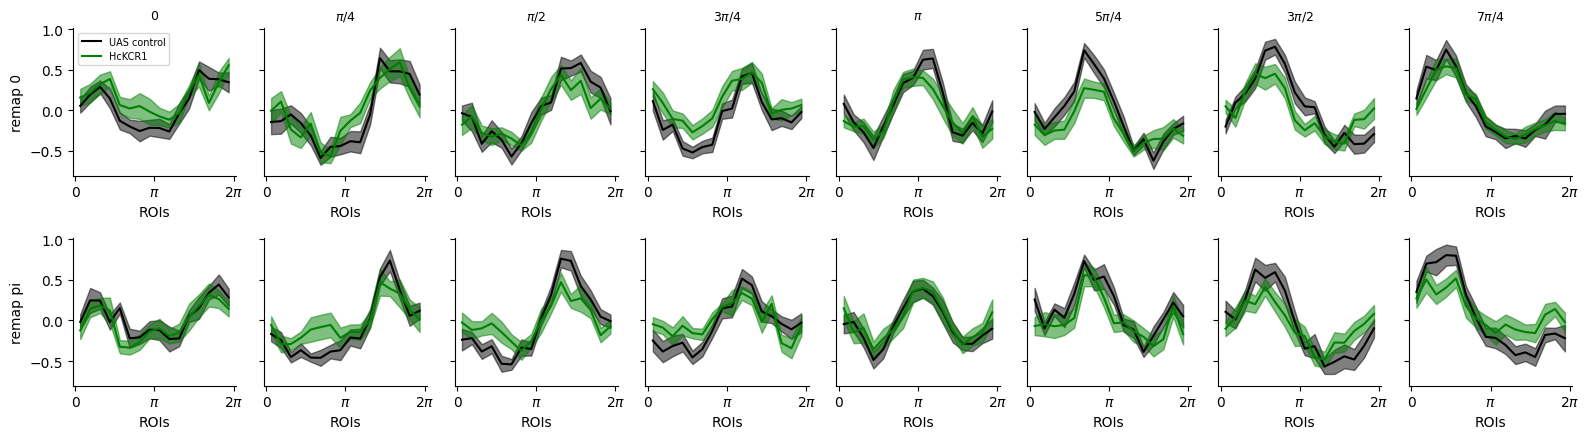

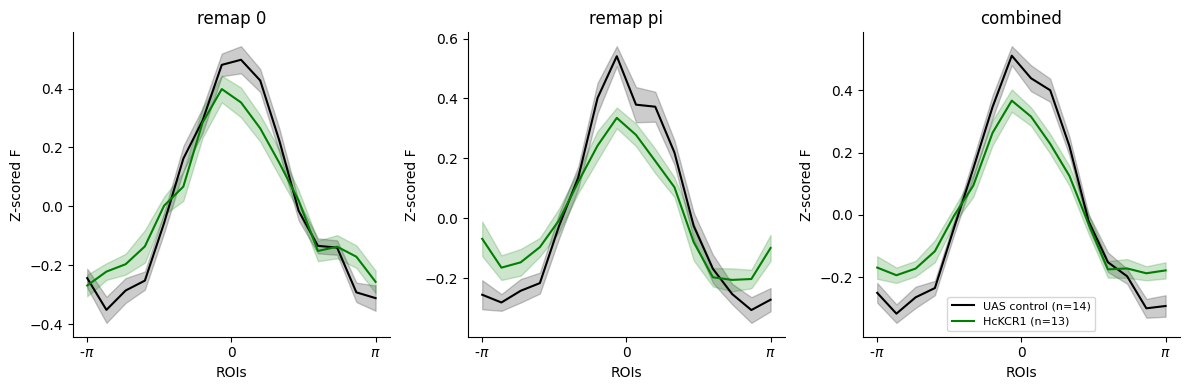

In [3]:
aligned_opto, opto_tables = ana.opto_analysis(sess_manager)
for name, table in opto_tables.items():
    print(name)
    display(table) if hasattr(table, 'columns') else print(table)

## Offset remapping

uas_control remap 0 -0.16752130285596087
uas_control remap 180 2.5593348804874587
hckcr1 remap 0 -0.9256520073385599
hckcr1 remap 180 -1.1254782781527923
remapping_error_tests


,family,comparison,n,W,p,p_holm
0,error vs chance,UAS control,13.0,1.0,0.000488,0.000977
1,error vs chance,HcKCR1,13.0,29.0,0.273438,0.273438
2,error between groups,UAS control vs HcKCR1,NaN,12.0,0.000222,0.000222


mean_offsets


,group,scan_type,n_flies,mean_offset,mean_vec_len
0,uas_control,baseline,14,0.366809,0.132612
1,uas_control,post_0deg,13,-0.167521,0.255585
2,uas_control,post_180deg,14,2.559335,0.191604
3,hckcr1,baseline,13,-0.742685,0.072254
4,hckcr1,post_0deg,13,-0.925652,0.100884
5,hckcr1,post_180deg,13,-1.125478,0.064508


n_flies


,group,n_flies
0,uas_control,14
1,hckcr1,13


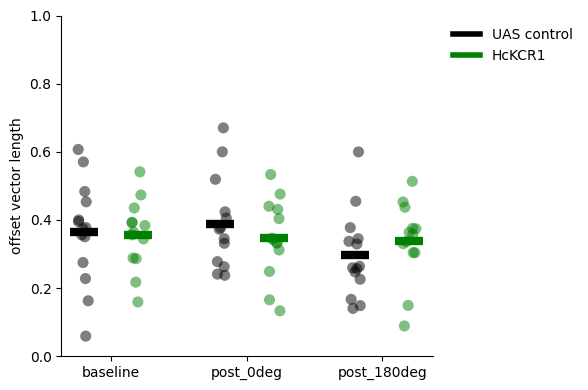

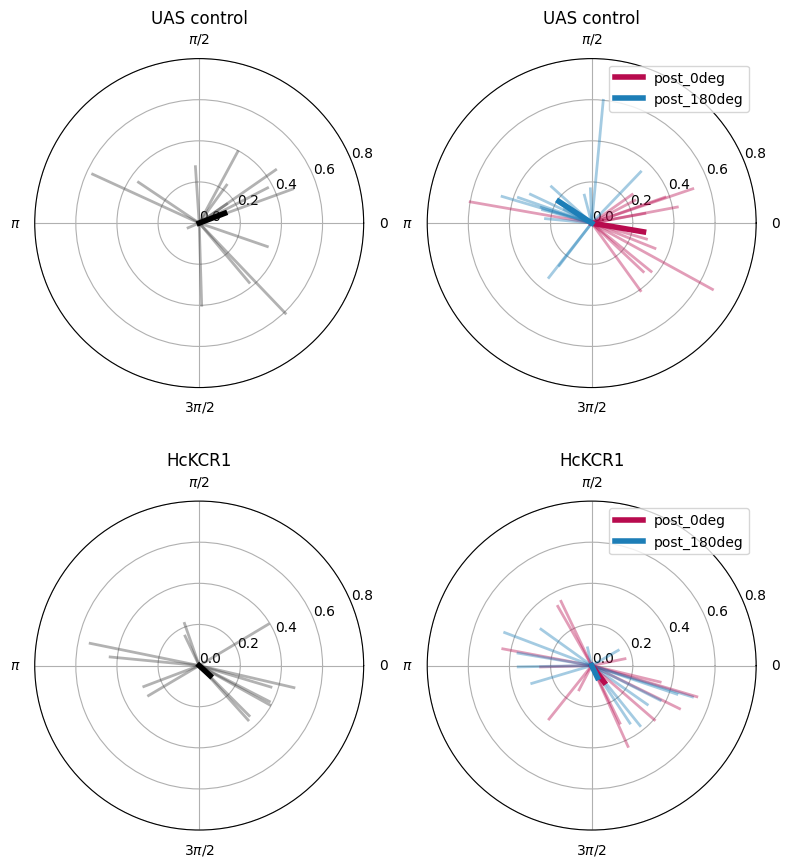

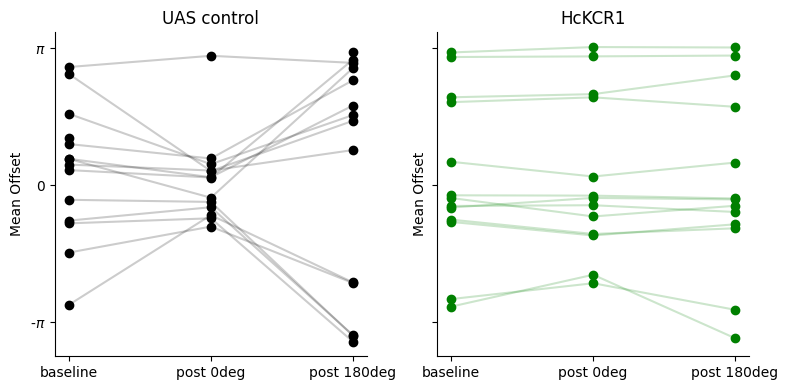

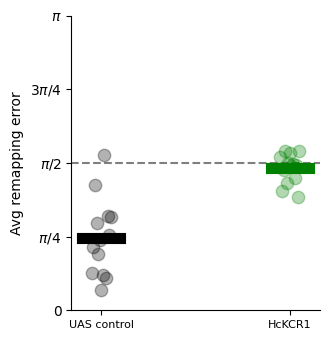

In [4]:
#ToDo: extend axes 
offset_summary, offset_tables = ana.offset_analysis(sess_manager)
for name, table in offset_tables.items():
    print(name)
    display(table) if hasattr(table, 'columns') else print(table)

## Heatmaps and offset histograms of every fly

In [5]:
plotted_flies = ana.plot_session_figures(sess_manager)
len(plotted_flies)

26